In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/PhreshPhish_Project"
)

FULL_DIR = PROJECT_DIR / "full_dataset_features"
FEATURE_DIR = PROJECT_DIR / "features"

print(FULL_DIR.exists())
print(FEATURE_DIR.exists())

True
True


In [9]:
%pip install -q pandas numpy matplotlib seaborn pyarrow

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [11]:
train_path = FULL_DIR / "train_full_features.parquet"
test_path = FULL_DIR / "test_full_features.parquet"

assert train_path.exists(), f"Missing file: {train_path}"
assert test_path.exists(), f"Missing file: {test_path}"

train = pd.read_parquet(train_path)
test = pd.read_parquet(test_path)

print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)

display(train.head())

Training dataset: (498255, 52)
Testing dataset: (168060, 52)


,source_row,label,hostname,html_sha256,html_parse_failed,url_length,hostname_length,path_length,query_length,fragment_length,path_depth,subdomain_count,digit_count,letter_count,special_char_count,dot_count,hyphen_count,underscore_count,slash_count,at_count,percent_count,question_count,equals_count,ampersand_count,digit_ratio,special_char_ratio,url_entropy,token_count,max_token_length,avg_token_length,hostname_is_ip,contains_punycode,has_query,html_length,html_tag_count,html_text_length,html_title_present,html_form_count,html_input_count,html_password_input_count,html_hidden_input_count,html_link_count,html_absolute_link_count,html_relative_link_count,html_empty_link_count,html_javascript_link_count,html_image_count,html_script_count,html_stylesheet_count,html_iframe_count,html_meta_refresh_count,html_button_count
0,0,benign,www.lifeonthemediterranean.com,c361661da533effdaac55163d61b7eec1accc840afdd08...,0,61,30,31,0,0,1,1,0,53,8,2,4,0,2,0,0,0,0,0,0.000000,0.131148,4.125181,8,22,6.625000,0,0,0,518982,1276,79889,1,2,14,0,4,159,128,22,9,0,93,38,1,12,0,5
1,1,benign,moneypuck.com,d5d7cb9bee19e1c377ab016d028d7bde0a3b80bfbf85f9...,0,25,13,12,0,0,1,0,0,22,3,2,0,0,1,0,0,0,0,0,0.000000,0.120000,4.023465,4,9,5.500000,0,0,0,192077,3227,38394,1,0,1,0,0,28,0,28,0,0,91,26,4,8,0,0
2,2,benign,learn.microsoft.com,875c5f5ded0d33fe0aab393f922ab48aa6119f05297c46...,0,81,19,62,0,0,4,1,0,69,12,2,6,0,4,0,0,0,0,0,0.000000,0.148148,3.981222,13,9,5.307692,0,0,0,164883,1512,32210,1,3,5,0,0,239,61,174,4,0,22,7,1,0,0,56
3,3,benign,www.grandcanyondestinations.com,68b4c3fa3839a9db7fd5f134115aefcb1edbd562e6452b...,0,58,31,27,0,0,1,1,0,50,8,2,4,0,2,0,0,0,0,0,0.000000,0.137931,4.012540,8,23,6.250000,0,0,0,216067,475,170687,1,2,7,0,3,79,71,4,4,0,18,39,6,2,0,1
4,4,benign,pgcps-md.safeschools.com,cfa9639309c5617b31888b47a24e87b2f989c0d77e3d27...,0,89,24,65,0,0,4,1,20,57,12,2,5,1,4,0,0,0,0,0,0.224719,0.134831,4.765295,13,12,5.923077,0,0,0,25199,260,11701,1,1,1,0,0,11,10,1,0,0,5,23,4,2,0,4


In [12]:
print("TRAINING DATA")
train.info()

print("\nTEST DATA")
test.info()

print("\nColumn names:")
print(train.columns.tolist())

print("\nData types:")
display(train.dtypes.value_counts().to_frame("Number of columns"))

TRAINING DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498255 entries, 0 to 498254
Data columns (total 52 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   source_row                  498255 non-null  int64  
 1   label                       498255 non-null  object 
 2   hostname                    498254 non-null  object 
 3   html_sha256                 498255 non-null  object 
 4   html_parse_failed           498255 non-null  int64  
 5   url_length                  498255 non-null  int64  
 6   hostname_length             498255 non-null  int64  
 7   path_length                 498255 non-null  int64  
 8   query_length                498255 non-null  int64  
 9   fragment_length             498255 non-null  int64  
 10  path_depth                  498255 non-null  int64  
 11  subdomain_count             498255 non-null  int64  
 12  digit_count                 498255 non-null  int64  
 13  

,Number of columns
int64,45
float64,4
object,3


In [13]:
target_candidates = ["label", "target", "class", "is_phishing"]

TARGET = next(
    (c for c in train.columns if c.lower() in target_candidates),
    None
)

print("Detected target:", TARGET)

# Exclude identifiers and metadata from numerical feature analysis.
metadata_words = [
    "url", "hostname", "domain", "html", "hash",
    "source_row", "date", "split", "lang", "id"
]

numeric_columns = train.select_dtypes(include=np.number).columns.tolist()

feature_columns = [
    c for c in numeric_columns
    if c != TARGET
    and not any(word in c.lower() for word in metadata_words)
]

print("Number of numerical columns:", len(numeric_columns))
print("Candidate numerical features:", len(feature_columns))
print(feature_columns)

Detected target: label
Number of numerical columns: 49
Candidate numerical features: 23
['path_length', 'query_length', 'fragment_length', 'path_depth', 'digit_count', 'letter_count', 'special_char_count', 'dot_count', 'hyphen_count', 'underscore_count', 'slash_count', 'at_count', 'percent_count', 'question_count', 'equals_count', 'ampersand_count', 'digit_ratio', 'special_char_ratio', 'token_count', 'max_token_length', 'avg_token_length', 'contains_punycode', 'has_query']


Training class distribution:


,Count
label,
benign,276729
phish,221526



Testing class distribution:


,Count
label,
benign,91260
phish,76800


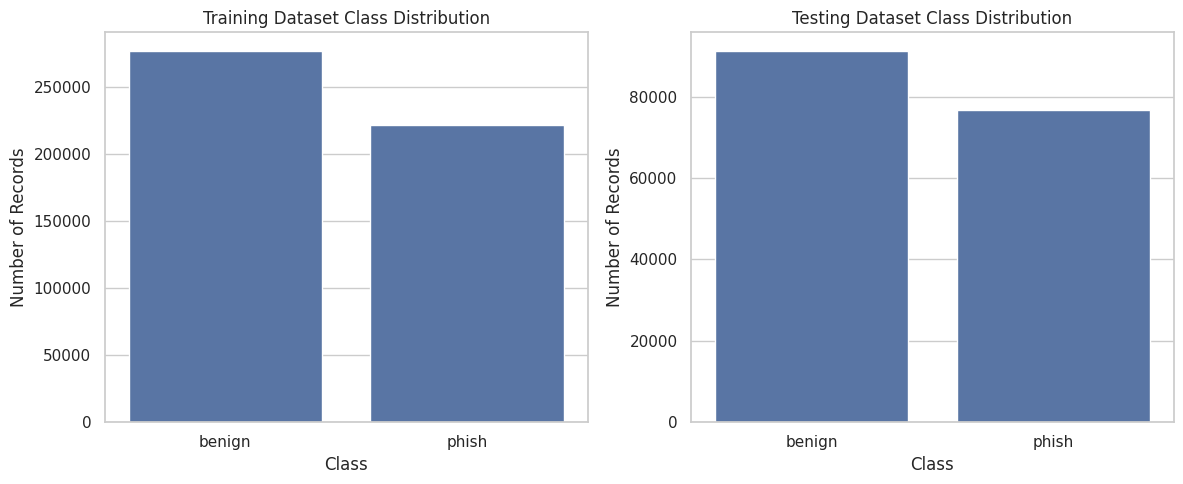

In [14]:
if TARGET is None:
    raise ValueError("Set TARGET to the correct label column before continuing.")

print("Training class distribution:")
display(train[TARGET].value_counts().to_frame("Count"))

print("\nTesting class distribution:")
display(test[TARGET].value_counts().to_frame("Count"))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=train, x=TARGET, ax=axes[0])
axes[0].set_title("Training Dataset Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Records")

sns.countplot(data=test, x=TARGET, ax=axes[1])
axes[1].set_title("Testing Dataset Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

In [15]:
quality = pd.DataFrame({
    "Train Missing": train.isnull().sum(),
    "Test Missing": test.reindex(columns=train.columns).isnull().sum(),
    "Unique Values": train.nunique(dropna=False),
    "Data Type": train.dtypes.astype(str)
})

display(quality.sort_values("Train Missing", ascending=False))

print("Duplicate training rows:", train.duplicated().sum())
print("Duplicate testing rows:", test.duplicated().sum())

constant_columns = train.columns[train.nunique(dropna=False) <= 1]
print("Constant columns:", constant_columns.tolist())

,Train Missing,Test Missing,Unique Values,Data Type
hostname,1,0,271486,object
source_row,0,0,498255,int64
label,0,0,2,object
html_sha256,0,0,452198,object
html_parse_failed,0,0,2,int64
url_length,0,0,727,int64
hostname_length,0,0,93,int64
path_length,0,0,496,int64
query_length,0,0,517,int64
fragment_length,0,0,79,int64


Duplicate training rows: 0
Duplicate testing rows: 0
Constant columns: []


In [16]:
feature_summary = train[feature_columns].describe().T

feature_summary["skewness"] = train[feature_columns].skew()
feature_summary["missing_percentage"] = (
    train[feature_columns].isnull().mean() * 100
)

display(feature_summary)

,count,mean,std,min,25%,50%,75%,max,skewness,missing_percentage
path_length,498255.0,26.554469,32.565857,0.000000,3.000000,18.000000,40.00000,3212.000000,9.759930,0.0
query_length,498255.0,1.880649,23.087145,0.000000,0.000000,0.000000,0.00000,2481.000000,33.655636,0.0
fragment_length,498255.0,0.159489,50.990422,0.000000,0.000000,0.000000,0.00000,25432.000000,498.027581,0.0
path_depth,498255.0,1.777853,1.684999,0.000000,1.000000,2.000000,3.00000,150.000000,7.295012,0.0
digit_count,498255.0,4.081874,14.219475,0.000000,0.000000,0.000000,5.00000,3413.000000,69.574874,0.0
letter_count,498255.0,38.745126,53.136469,0.000000,23.000000,32.000000,48.00000,22016.000000,286.153175,0.0
special_char_count,498255.0,6.703184,5.372260,1.000000,4.000000,5.000000,8.00000,642.000000,12.257345,0.0
dot_count,498255.0,2.095417,0.773626,1.000000,2.000000,2.000000,2.00000,42.000000,3.211812,0.0
hyphen_count,498255.0,1.892581,3.060618,0.000000,0.000000,1.000000,3.00000,100.000000,4.987647,0.0
underscore_count,498255.0,0.210192,1.006362,0.000000,0.000000,0.000000,0.00000,66.000000,9.848183,0.0


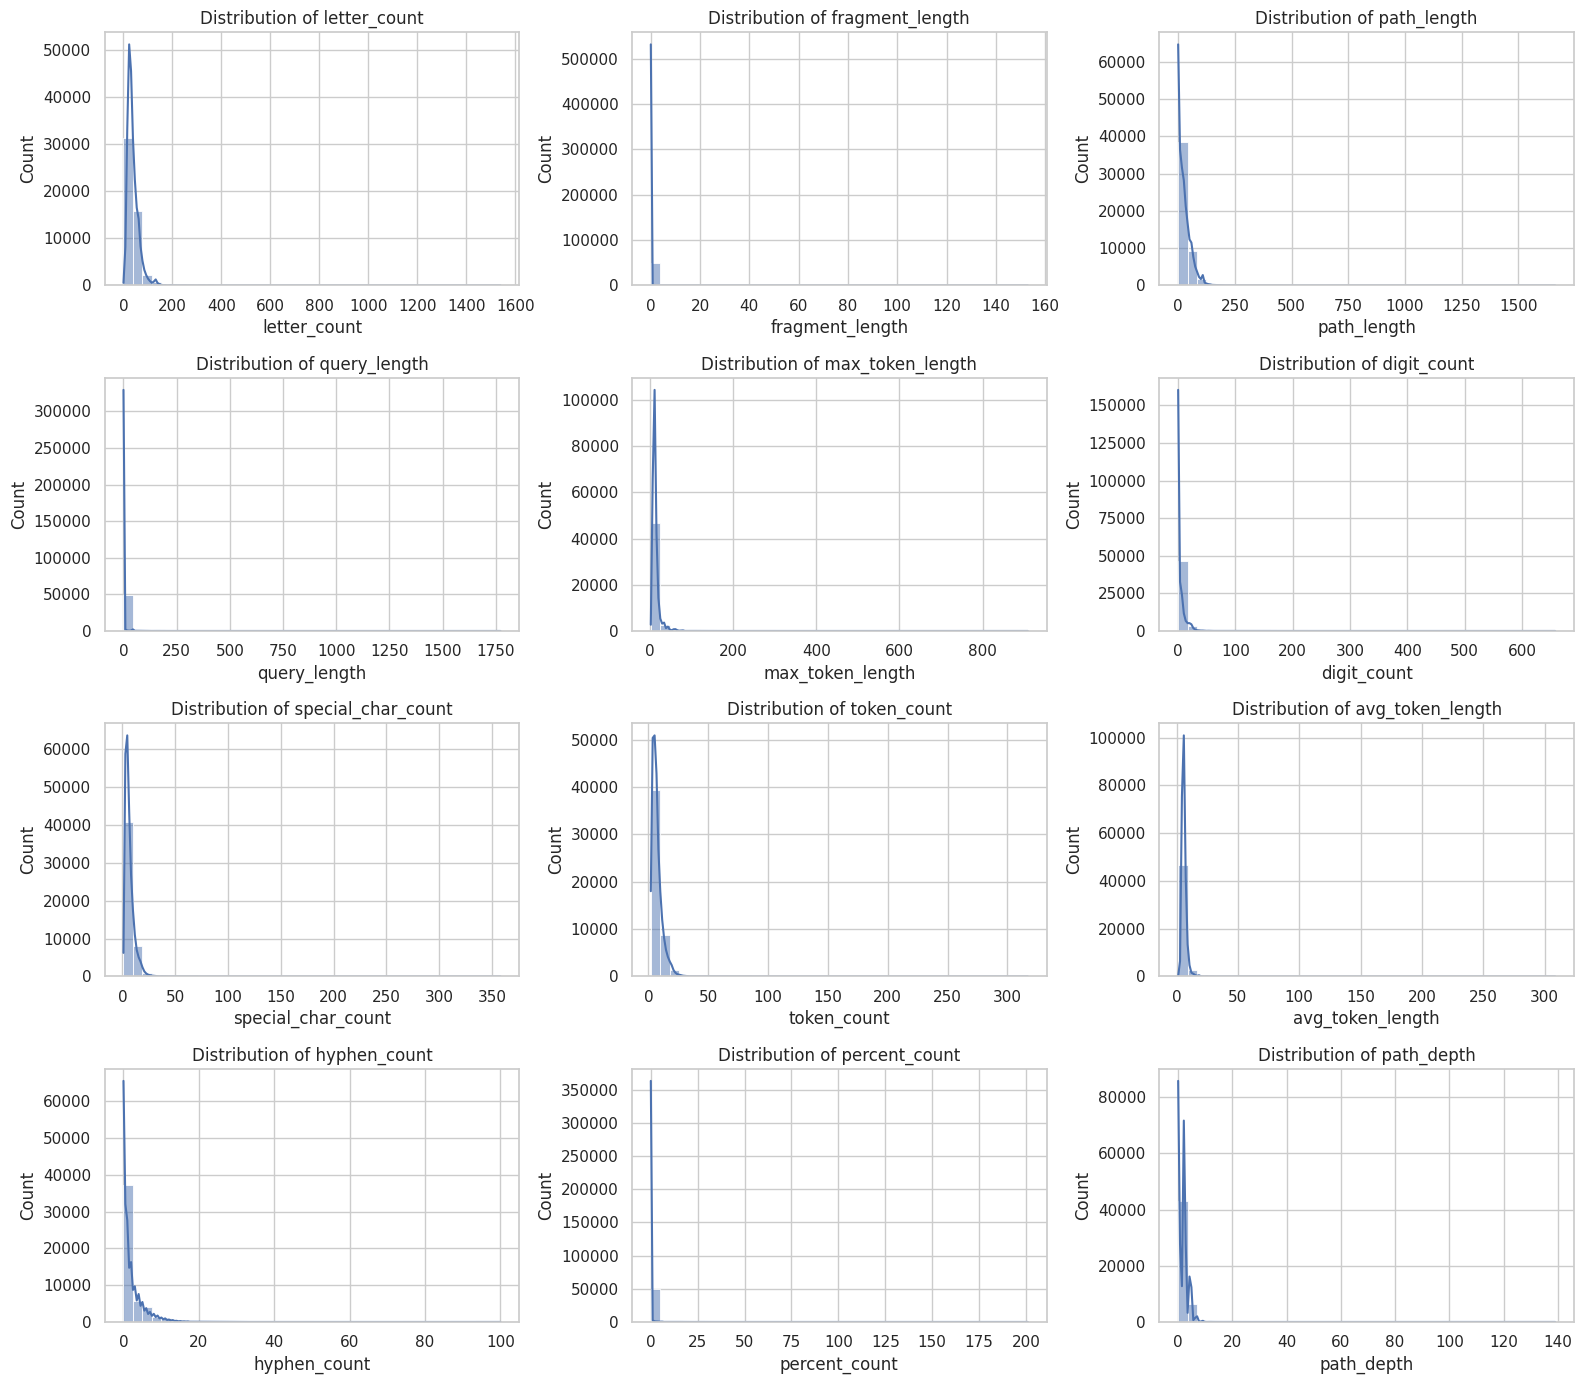

In [17]:
plot_sample = train.sample(
    n=min(50000, len(train)),
    random_state=42
)

selected_features = (
    train[feature_columns]
    .var()
    .sort_values(ascending=False)
    .head(min(12, len(feature_columns)))
    .index.tolist()
)

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for ax, col in zip(axes, selected_features):
    sns.histplot(
        data=plot_sample,
        x=col,
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

for ax in axes[len(selected_features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

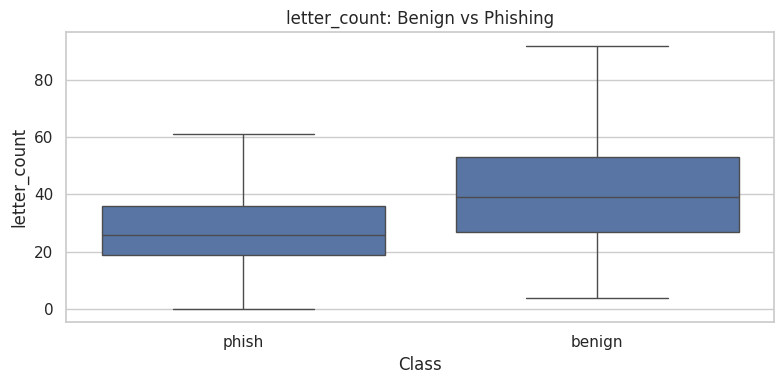

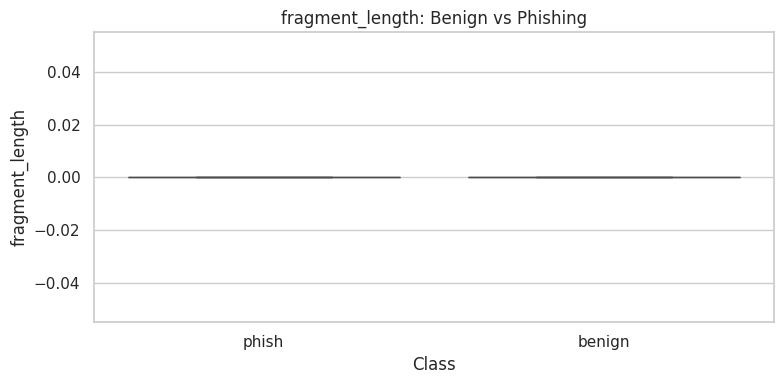

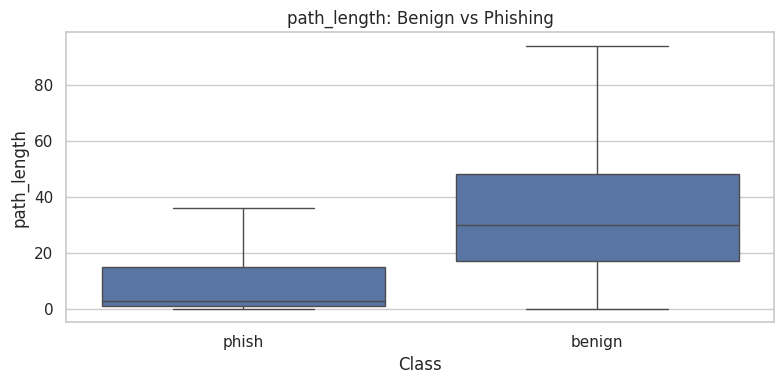

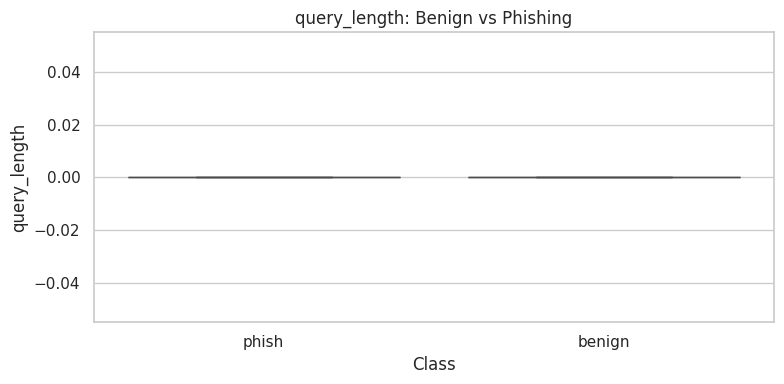

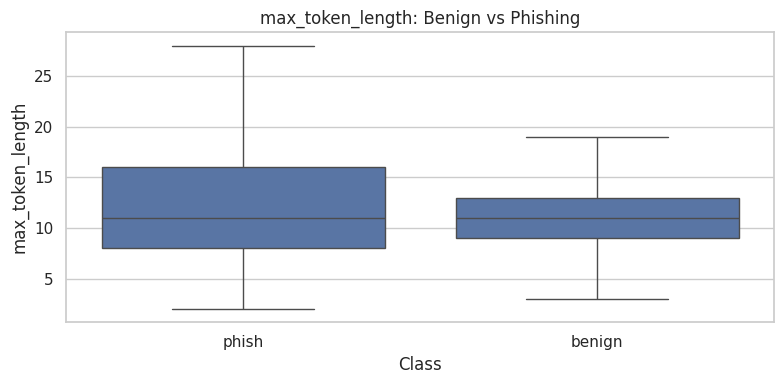

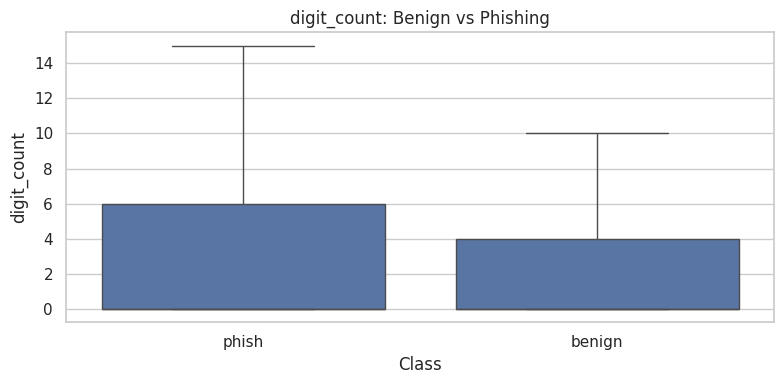

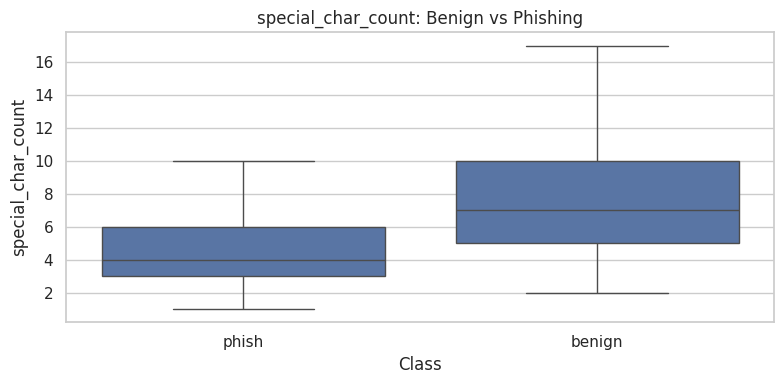

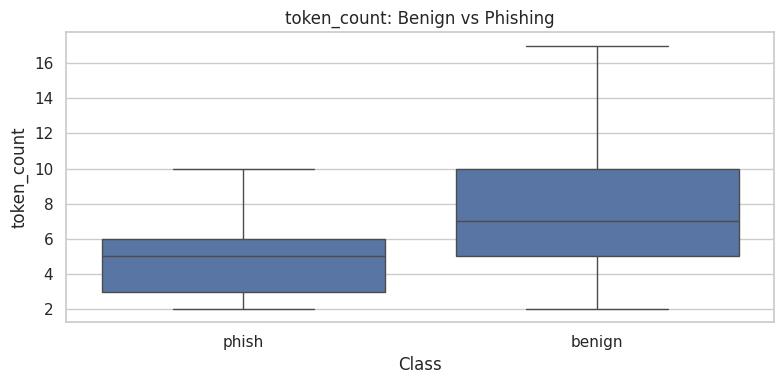

In [18]:
class_plot_features = selected_features[:8]

for col in class_plot_features:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=plot_sample,
        x=TARGET,
        y=col,
        showfliers=False
    )

    plt.title(f"{col}: Benign vs Phishing")
    plt.xlabel("Class")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

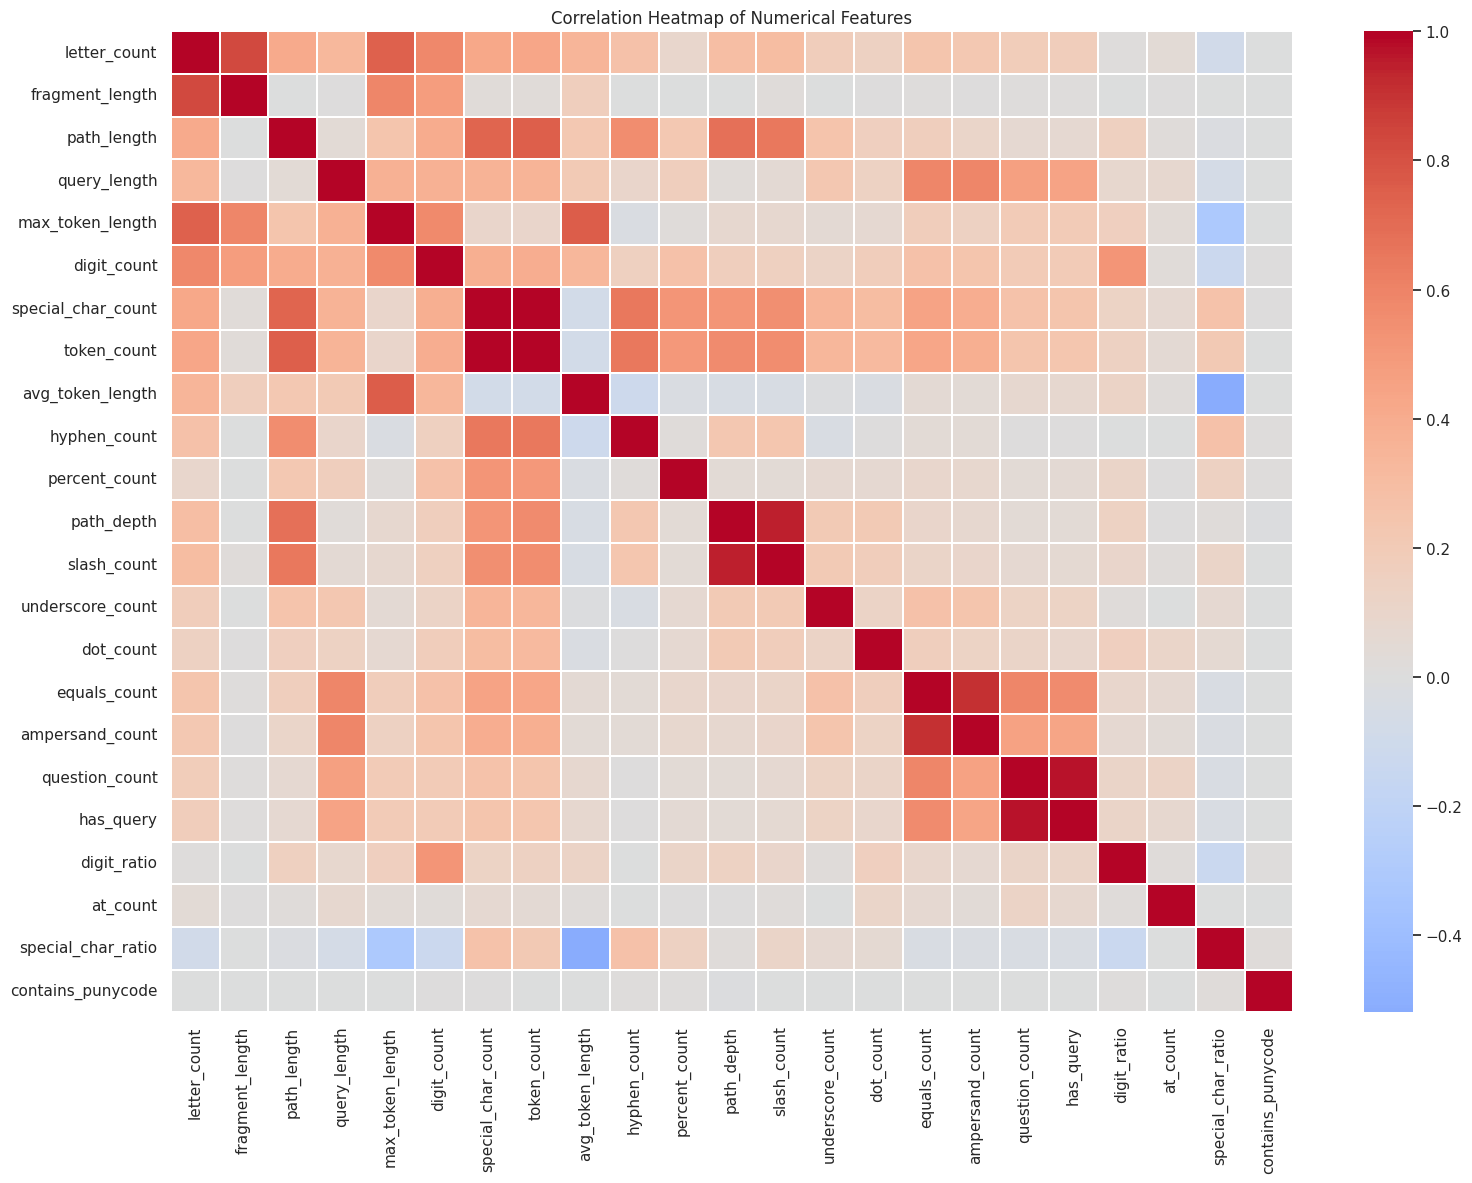

In [19]:
correlation_features = (
    train[feature_columns]
    .var()
    .sort_values(ascending=False)
    .head(min(25, len(feature_columns)))
    .index
)

correlation_matrix = train[correlation_features].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [20]:
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .loc[lambda x: x.abs() >= 0.90]
    .sort_values(key=abs, ascending=False)
)

print("Feature pairs with correlation >= 0.90 or <= -0.90:")
display(high_correlations.to_frame("Correlation"))

Feature pairs with correlation >= 0.90 or <= -0.90:


,,Correlation
special_char_count,token_count,0.990940
question_count,has_query,0.964564
path_depth,slash_count,0.950430
equals_count,ampersand_count,0.908106


In [21]:
feature_tables = {}

for split in ["train", "test"]:
    for group in ["url", "html", "hybrid"]:
        path = FEATURE_DIR / f"{split}_{group}_features.csv"

        if path.exists():
            df = pd.read_csv(path)
            feature_tables[f"{split}_{group}"] = df

            print(f"\n{path.name}")
            print("Shape:", df.shape)
            print("Missing values:", df.isnull().sum().sum())
            print("Columns:", len(df.columns))
        else:
            print("Not found:", path)


train_url_features.csv
Shape: (50000, 32)
Missing values: 0
Columns: 32

train_html_features.csv
Shape: (50000, 23)
Missing values: 0
Columns: 23

train_hybrid_features.csv
Shape: (50000, 53)
Missing values: 0
Columns: 53

test_url_features.csv
Shape: (15000, 32)
Missing values: 0
Columns: 32

test_html_features.csv
Shape: (15000, 23)
Missing values: 0
Columns: 23

test_hybrid_features.csv
Shape: (15000, 53)
Missing values: 0
Columns: 53


In [22]:
result_files = [
    "full_train_validation_split.csv",
    "full_data_threshold_comparison.csv",
    "learning_curve_results.csv"
]

for filename in result_files:
    path = FULL_DIR / filename

    if path.exists():
        df = pd.read_csv(path)

        print(f"\n{filename}")
        display(df.head(10))
    else:
        print(f"Not found: {filename}")


full_train_validation_split.csv


,source_row,label,hostname,domain_group,partition
0,0,benign,www.lifeonthemediterranean.com,lifeonthemediterranean.com,train
1,1,benign,moneypuck.com,moneypuck.com,train
2,2,benign,learn.microsoft.com,microsoft.com,train
3,3,benign,www.grandcanyondestinations.com,grandcanyondestinations.com,train
4,4,benign,pgcps-md.safeschools.com,safeschools.com,validation
5,5,benign,screenrant.com,screenrant.com,train
6,6,benign,blog.hobartcorp.com,hobartcorp.com,validation
7,7,phish,www-thediamondempirellc-com.filesusr.com,filesusr.com,train
8,8,phish,user-confirmation.fanpages-improve365823.com,fanpages-improve365823.com,validation
9,9,benign,www.unitedsiteservices.com,unitedsiteservices.com,train



full_data_threshold_comparison.csv


,threshold,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,0.05,0.892956,0.812485,0.989446,0.892276,0.185372,473,10234
1,0.06,0.903033,0.828485,0.988152,0.901302,0.166063,531,9168
2,0.07,0.910801,0.841353,0.987036,0.908391,0.151083,581,8341
3,0.08,0.917190,0.852438,0.985831,0.914295,0.138531,635,7648
4,0.09,0.922209,0.861395,0.984849,0.918994,0.128641,679,7102
5,0.10,0.926198,0.868910,0.983689,0.922744,0.120472,731,6651
6,0.11,0.929307,0.875117,0.982417,0.925668,0.113806,788,6283
7,0.12,0.932606,0.881796,0.981100,0.928802,0.106760,847,5894
8,0.13,0.935276,0.887669,0.979494,0.931323,0.100619,919,5555
9,0.14,0.937675,0.893116,0.977932,0.933602,0.095004,989,5245



learning_curve_results.csv


,training_size,split,accuracy,precision,recall,f1,fpr,false_negatives,false_positives
0,40000,Train,0.983300,0.985528,0.976769,0.981129,0.011475,413,255
1,40000,Validation,0.935435,0.967940,0.885220,0.924734,0.023801,5144,1314
2,100000,Train,0.977660,0.980282,0.969429,0.974825,0.015709,1364,870
3,100000,Validation,0.928487,0.960372,0.876562,0.916555,0.029362,5532,1621
4,200000,Train,0.975475,0.978091,0.966348,0.972184,0.017251,2985,1920
5,200000,Validation,0.925628,0.968090,0.862438,0.912215,0.023076,6165,1274
6,300000,Train,0.975367,0.977599,0.966662,0.972100,0.017684,4440,2950
7,300000,Validation,0.928657,0.969404,0.868172,0.916000,0.022243,5908,1228
8,398231,Train,0.974701,0.976582,0.966154,0.971340,0.018481,5981,4094
9,398231,Validation,0.927307,0.969324,0.865137,0.914272,0.022225,6044,1227
